# Notebook 2 — Offline Evaluation of Small Open-Weight LLMs (RQ1–RQ4 + deployability)

In [1]:
# ── 1. Setup + environment detect (Colab / Kaggle / local) ─
import os, sys, re, json, time, math, glob, hashlib, random, subprocess, gc, warnings, shutil
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = os.path.exists('/kaggle/working')
ENV = 'colab' if IN_COLAB else 'kaggle' if IN_KAGGLE else 'local'
if ENV in ('colab', 'kaggle'):
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'bitsandbytes>=0.43',
                    'sentence-transformers>=3.0', 'statsmodels'], check=True)
if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount('/content/drive')

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm
warnings.filterwarnings('ignore', category=FutureWarning)
try:
    import torch
    GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
except ImportError:
    torch, GPU_NAME = None, 'none'
print(f'ENV: {ENV} | GPU: {GPU_NAME}')

def secret(name):
    if IN_COLAB: return userdata.get(name)
    if IN_KAGGLE:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    return os.environ.get(name)

ENV: kaggle | GPU: Tesla T4


In [2]:
# ── 2. Config (edit only this cell) ───────────────────────
PIPELINE_TEST     = False      # True = test the pipeline with fake models (no GPU needed)
#RUN_MODELS        = ['qwen2.5-7b']   # models for this run: 'qwen2.5-7b' | 'qwen2.5-3b' | 'llama3.1-8b' | 'gemma2-9b'
#RUN_MODELS        = ['qwen2.5-3b']
#RUN_MODELS        = ['gemma2-9b']
#RUN_MODELS        = ['llama3.1-8b']
RUN_MODELS        = []
SEED              = 42
USE_ONLY_VERIFIED = True       # use only items with verified=yes and bn_verified=yes
LANGS             = ['en', 'bn']
SETTINGS          = ['zeroshot', 'rag_generic', 'rag_country']
TOP_K             = 4
EMB_MODEL         = 'BAAI/bge-m3'   # multilingual (covers Bangla), MIT licence
LABEL_SOURCES     = True
PROMPT_VERSION    = 'v1'       # change this if prompts change -> everything re-runs

# model tag -> Hugging Face id and licence (report licences in the paper)
HF_MODELS = {
    'qwen2.5-7b':  dict(id='Qwen/Qwen2.5-7B-Instruct',         license='Apache-2.0',          gated=False),
    'qwen2.5-3b':  dict(id='Qwen/Qwen2.5-3B-Instruct',         license='Qwen Research',       gated=False),
    'llama3.1-8b': dict(id='meta-llama/Llama-3.1-8B-Instruct', license='Llama 3.1 Community', gated=True),
    'gemma2-9b':   dict(id='google/gemma-2-9b-it',             license='Gemma Terms of Use',  gated=True),
}
QUANT          = '4bit'        # paper setting: all models in 4-bit NF4 for a fair comparison
HF_BATCH       = 1             # 1 = save after every item and clean per-item timing
MAX_NEW_TOKENS = 24
N_BOOT         = 2000

# which model drafted each item (draft_model column); evaluated drafters are flagged in tables
DRAFTER_EVALUATED = {'qwen2.5-7b'}                 # drafter that is also evaluated -> marked †
DRAFTER_FAMILY    = {'qwen2.5-3b': 'qwen2.5-7b'}   # same family as a drafter -> marked ‡

DISPLAY = {'qwen2.5-7b': 'Qwen2.5-7B', 'qwen2.5-3b': 'Qwen2.5-3B', 'llama3.1-8b': 'Llama-3.1-8B',
           'gemma2-9b': 'Gemma-2-9B', 'mock-a': 'Mock-A', 'mock-b': 'Mock-B'}
MODEL_ORDER = list(DISPLAY)
SETTING_NAME = {'zeroshot': 'Zero-shot', 'rag_generic': 'Generic RAG', 'rag_country': 'Country RAG'}
LANG_NAME = {'en': 'English', 'bn': 'Bangla'}

In [3]:
# ── 3. Paths (auto), seed ──────────────────────────────────
if IN_COLAB:
    BASE = '/content/drive/MyDrive/DengueLLM'; DATA_DIR = f'{BASE}/data'
elif IN_KAGGLE:
    BASE = '/kaggle/working/DengueLLM'
    hits = glob.glob('/kaggle/input/**/benchmark.csv', recursive=True)
    DATA_DIR = os.path.dirname(hits[0]) if hits else f'{BASE}/data'
    if not hits and not PIPELINE_TEST: print('STOP: benchmark.csv not found under /kaggle/input - add your dataset as an input')
else:
    BASE = os.path.abspath(os.environ.get('DENGUE_BASE', 'DengueLLM')); DATA_DIR = f'{BASE}/data'
OUT = f'{BASE}/eval_test' if PIPELINE_TEST else f'{BASE}/eval'
RES_DIR, TAB_DIR, FIG_DIR = f'{OUT}/raw', f'{OUT}/tables', f'{OUT}/figures'
for d in [RES_DIR, TAB_DIR, FIG_DIR]: os.makedirs(d, exist_ok=True)

# Kaggle: copy raw files from a previous version's output (added as input) to resume
if IN_KAGGLE and not PIPELINE_TEST:
    for f in glob.glob('/kaggle/input/**/raw_*.csv', recursive=True) + glob.glob('/kaggle/input/**/deploy_*.csv', recursive=True):
        dst = f'{RES_DIR}/{os.path.basename(f)}'
        if not os.path.exists(dst) or os.path.getsize(f) > os.path.getsize(dst):
            shutil.copy(f, dst); print('↺ resume from', f)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); os.environ['PYTHONHASHSEED'] = str(s)
    if torch is not None:
        torch.manual_seed(s)
        if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
print('Data  →', DATA_DIR, '\nOutput →', OUT, '| TEST MODE' if PIPELINE_TEST else '')

↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/raw_gemma2-9b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/raw_llama3.1-8b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/raw_qwen2.5-7b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/raw_qwen2.5-3b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/deploy_qwen2.5-7b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/deploy_llama3.1-8b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/deploy_qwen2.5-3b.csv
↺ resume from /kaggle/input/notebooks/sayemchowdhury23/nb2-llm-evaluation-final/DengueLLM/eval/raw/deploy_gemma2-9b.csv
Data  → /kaggle/input/datasets/sayemchowdhur

## 3. Load data (benchmark + chunks)

In [4]:
# ── 3b. Load benchmark & corpus ────────────────────────────
L4 = list('ABCD')

def make_synthetic():
    # PIPELINE_TEST only: synthetic data, never used for the paper
    rng = random.Random(SEED)
    topics = ['fluid', 'platelet_tx', 'warning_signs', 'shock', 'discharge', 'drugs_avoid']
    ch = []
    for c, src in [('BD', 'BD_2018'), ('IN', 'IN_2023')]:
        for i in range(20):
            t = topics[i % len(topics)]
            ch.append({'chunk_id': f'{c}_{len(ch):04d}', 'country': c, 'source': src, 'page_start': i + 1,
                       'page_end': i + 2, 'text': f'{c} guideline section on {t}. Rule {i}: give {rng.randint(5, 20)} ml/kg. ' * 15})
    rows = []
    for k in range(18):
        s = ['BD', 'IN', 'CONFLICT'][k % 3]; t = topics[k % len(topics)]
        a_bd = rng.choice(L4) if s in ('BD', 'CONFLICT') else ''
        a_in = (rng.choice([x for x in L4 if x != a_bd]) if s == 'CONFLICT' else rng.choice(L4)) if s in ('IN', 'CONFLICT') else ''
        r = {'qid': f'Q{k+1:03d}', 'set': s, 'topic': t,
             'question_en': f'Test question {k} about {t}?', 'question_bn': f'{t} বিষয়ে পরীক্ষামূলক প্রশ্ন {k}?',
             'answer_BD': a_bd, 'answer_IN': a_in, 'page_BD': str(k % 20 + 1) if a_bd else '',
             'page_IN': str(k % 20 + 1) if a_in else '', 'evidence_quote': '', 'draft_by': 'llm' if k % 3 else 'human',
             'draft_model': ['', 'gemini-2.5-flash', 'qwen2.5-7b'][k % 3],
             'verified': 'yes', 'bn_verified': 'yes', 'notes': ''}
        for x in L4: r[f'{x}_en'] = f'option {x}{k}'; r[f'{x}_bn'] = f'বিকল্প {x}{k}'
        rows.append(r)
    return pd.DataFrame(rows), pd.DataFrame(ch)

if PIPELINE_TEST:
    bench_all, chunks = make_synthetic()
else:
    bench_all = pd.read_csv(f'{DATA_DIR}/benchmark.csv', dtype=str).fillna('')
    chunks = pd.read_json(f'{DATA_DIR}/corpus_chunks.jsonl', lines=True, dtype={'chunk_id': str})

for c in ['answer_BD', 'answer_IN']:
    bench_all[c] = bench_all[c].str.strip().str.upper()
bench_all['draft_by'] = bench_all['draft_by'].replace('', 'unknown')
if 'draft_model' not in bench_all: bench_all['draft_model'] = ''
# drafter = who drafted the item: human / gemini-2.5-flash / qwen2.5-7b / claude / llm-unknown
bench_all['drafter'] = np.where(bench_all.draft_by == 'llm',
                                bench_all.draft_model.replace('', 'llm-unknown'), bench_all.draft_by)
bench = bench_all[(bench_all.verified == 'yes') & (bench_all.bn_verified == 'yes')] if USE_ONLY_VERIFIED else bench_all
bench = bench.reset_index(drop=True)
chunks = chunks.reset_index(drop=True)

print(f'Benchmark: {len(bench_all)} items in file -> {len(bench)} used')
print(bench.groupby(['set', 'drafter']).size().unstack(fill_value=0))
print('Chunks:', chunks.groupby('country').size().to_dict(), '| sources:', chunks.source.unique().tolist())
assert len(bench), 'No verified items - verify items in NB1, or set USE_ONLY_VERIFIED=False (testing only)'
bad = bench[(bench.set == 'CONFLICT') & (bench.answer_BD == bench.answer_IN)]
assert bad.empty, f'CONFLICT items with identical answers: {bad.qid.tolist()}'

Benchmark: 128 items in file -> 128 used
drafter   claude  gemini-2.5-flash  qwen2.5-7b
set                                           
BD            30                25          12
CONFLICT       7                 0           0
IN            18                25          11
Chunks: {'BD': 83, 'IN': 80} | sources: ['BD_2018', 'IN_2023']


In [5]:
# ── 3c. Evaluation units ───────────────────────────────────
# CONFLICT items are asked twice: once with the patient in Bangladesh, once in India
def item_hash(r, lang):
    s = '|'.join([r[f'question_{lang}']] + [r[f'{x}_{lang}'] for x in L4] + [r['answer_BD'], r['answer_IN']])
    return hashlib.md5(s.encode('utf-8')).hexdigest()[:10]

def parse_pages(s):
    out = set()
    for a, b in re.findall(r'(\d+)\s*[-–]\s*(\d+)', str(s)): out |= set(range(int(a), int(b) + 1))
    out |= {int(x) for x in re.findall(r'\d+', re.sub(r'(\d+)\s*[-–]\s*(\d+)', '', str(s)))}
    return out

UNITS = []
for _, r in bench.iterrows():
    conflict = r['set'] == 'CONFLICT'
    for c in (['BD', 'IN'] if conflict else [r['set']]):
        oth = 'IN' if c == 'BD' else 'BD'
        for lang in LANGS:
            UNITS.append(dict(uid=f"{r['qid']}|{c}|{lang}", qid=r['qid'], set=r['set'],
                              subset=f'CONFLICT-{c}' if conflict else c, country=c, lang=lang,
                              topic=r['topic'], draft_by=r['draft_by'], drafter=r['drafter'], gold=r[f'answer_{c}'],
                              other_gold=r[f'answer_{oth}'] if conflict else '',
                              question=r[f'question_{lang}'], options={x: r[f'{x}_{lang}'] for x in L4},
                              pages=parse_pages(r[f'page_{c}']), ihash=item_hash(r, lang)))
UNIT = {u['uid']: u for u in UNITS}
print(f'{len(UNITS)} units × {len(SETTINGS)} settings = {len(UNITS) * len(SETTINGS)} calls/model')

270 units × 3 settings = 810 calls/model


## 4. Retrieval (bge-m3, Bangla query → English guideline text)

In [6]:
# ── 4. Embed chunks + queries, retrieve top-k ─────────────
def load_embedder():
    if PIPELINE_TEST:
        from sklearn.feature_extraction.text import HashingVectorizer
        hv = HashingVectorizer(analyzer='char_wb', ngram_range=(2, 4), n_features=2**14, alternate_sign=False, norm='l2')
        return lambda texts: hv.transform(texts).toarray().astype(np.float32)
    from sentence_transformers import SentenceTransformer
    dev = 'cuda' if torch is not None and torch.cuda.is_available() else 'cpu'
    m = SentenceTransformer(EMB_MODEL, device=dev)
    m.max_seq_length = 512
    if dev == 'cuda': m.half()
    enc = lambda texts: m.encode(texts, batch_size=16, normalize_embeddings=True,
                                 convert_to_numpy=True, show_progress_bar=len(texts) > 64).astype(np.float32)
    enc.model = m
    return enc

chunk_sig = hashlib.md5(('|'.join(chunks.chunk_id) + EMB_MODEL + str(len(''.join(chunks.text)))).encode()).hexdigest()[:10]
emb_path = f'{OUT}/chunk_emb_{chunk_sig}.npy'
embed = load_embedder()
if os.path.exists(emb_path):
    C = np.load(emb_path); print('chunk embeddings loaded from cache')
else:
    C = embed(chunks.text.tolist()); np.save(emb_path, C)

def query_text(u):
    return u['question'] + '\n' + '\n'.join(f'{x}. {u["options"][x]}' for x in L4)

qkeys = sorted({(u['qid'], u['lang']) for u in UNITS})
first = {}
for u in UNITS: first.setdefault((u['qid'], u['lang']), u)
Q = embed([query_text(first[k]) for k in qkeys])
QI = {k: i for i, k in enumerate(qkeys)}
S = Q @ C.T
is_country = {c: (chunks.country.values == c) for c in ['BD', 'IN']}

RETR, rlog = {}, []
for u in UNITS:
    s = S[QI[(u['qid'], u['lang'])]]
    for setting in [x for x in SETTINGS if x != 'zeroshot']:
        sc = s if setting == 'rag_generic' else np.where(is_country[u['country']], s, -np.inf)
        top = np.argsort(-sc)[:TOP_K]
        RETR[(u['uid'], setting)] = top.tolist()
        hit = any(chunks.country[i] == u['country'] and
                  any(chunks.page_start[i] <= p <= chunks.page_end[i] for p in u['pages']) for i in top)
        rlog.append(dict(uid=u['uid'], qid=u['qid'], lang=u['lang'], country=u['country'], setting=setting,
                         chunk_ids=';'.join(chunks.chunk_id[i] for i in top),
                         n_target_country=int(sum(chunks.country[i] == u['country'] for i in top)),
                         evidence_hit=int(hit) if u['pages'] else np.nan))
retr_df = pd.DataFrame(rlog)
retr_df.to_csv(f'{OUT}/retrieval_log.csv', index=False)
print(retr_df.groupby(['setting', 'lang'])[['evidence_hit', 'n_target_country']].mean().round(2))

if hasattr(embed, 'model'):   # free GPU memory before loading the LLM
    del embed.model
del embed; gc.collect()
if torch is not None and torch.cuda.is_available(): torch.cuda.empty_cache()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (10 outputs left out)

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

                  evidence_hit  n_target_country
setting     lang                                
rag_country bn            0.92              4.00
            en            0.96              4.00
rag_generic bn            0.79              2.40
            en            0.85              2.44


## 5. Prompts (English / Bangla) and answer parser

In [7]:
# ── 5. Prompts ─────────────────────────────────────────────
SRC_NAME = {'BD_2025': 'DGHS Bangladesh, 5th ed. 2025', 'BD_2018': 'DGHS Bangladesh, 4th ed. 2018',
            'IN_2023': 'NCVBDC India, 2023'}
CN = {'BD': dict(en='Bangladesh', loc='বাংলাদেশে', gen='বাংলাদেশের'),
      'IN': dict(en='India', loc='ভারতে', gen='ভারতের')}

SYS = {'en': ('You are a clinical decision-support assistant. Answer multiple-choice questions on the clinical '
              "management of dengue according to the national dengue clinical guideline of the patient's country."),
       'bn': ('আপনি একজন ক্লিনিক্যাল সহায়ক। রোগীর দেশের জাতীয় ডেঙ্গু ক্লিনিক্যাল গাইডলাইন অনুযায়ী '
              'ডেঙ্গুর চিকিৎসা-বিষয়ক বহুনির্বাচনী প্রশ্নের উত্তর দিন।')}

def fmt_passage(k, row):
    if LABEL_SOURCES:
        return f'[Passage {k} | {SRC_NAME.get(row.source, row.source)}, p. {row.page_start}-{row.page_end}]\n{row.text}'
    return f'[Passage {k}]\n{row.text}'

def build_prompt(u, setting):
    ids = [] if setting == 'zeroshot' else RETR[(u['uid'], setting)]
    ctx = '\n\n'.join(fmt_passage(k + 1, chunks.iloc[i]) for k, i in enumerate(ids))
    opts = '\n'.join(f'{x}. {u["options"][x]}' for x in L4)
    c = CN[u['country']]
    if u['lang'] == 'en':
        p = f"The patient is being treated in {c['en']}. Follow the national dengue clinical guideline of {c['en']}.\n\n"
        if ids: p += f'Use the following guideline excerpts:\n\n{ctx}\n\n'
        p += f"Question: {u['question']}\n{opts}\n\n"
        p += 'Reply with only the letter of the correct option (A, B, C or D) in the form "Answer: X".'
    else:
        p = f"রোগী {c['loc']} চিকিৎসাধীন। {c['gen']} জাতীয় ডেঙ্গু ক্লিনিক্যাল গাইডলাইন অনুসরণ করুন।\n\n"
        if ids: p += f'নিচের গাইডলাইন অংশগুলো ব্যবহার করুন:\n\n{ctx}\n\n'
        p += f"প্রশ্ন: {u['question']}\n{opts}\n\n"
        p += 'শুধু সঠিক বিকল্পের অক্ষরটি (A, B, C বা D) লিখুন, এই ফরম্যাটে: "উত্তর: X"'
    return SYS[u['lang']], p, ids

JOBS = []
for u in UNITS:
    for s in SETTINGS:
        sysmsg, user, ids = build_prompt(u, s)
        JOBS.append({**{k: v for k, v in u.items() if k not in ('options', 'pages')},
                     'key': f"{u['uid']}|{s}", 'setting': s, 'system': sysmsg, 'user': user,
                     'ctx_chunk_ids': ';'.join(chunks.chunk_id[i] for i in ids)})
print(len(JOBS), 'jobs\n\n---- sample prompt (bn, rag_country) ----')
ex = next(j for j in JOBS if j['lang'] == 'bn' and j['setting'] == 'rag_country')
print(ex['user'][:900], '...')

810 jobs

---- sample prompt (bn, rag_country) ----
রোগী বাংলাদেশে চিকিৎসাধীন। বাংলাদেশের জাতীয় ডেঙ্গু ক্লিনিক্যাল গাইডলাইন অনুসরণ করুন।

নিচের গাইডলাইন অংশগুলো ব্যবহার করুন:

[Passage 1 | DGHS Bangladesh, 4th ed. 2018, p. 48-49]
changes. • Bleeding: epistaxis, black stool, haematemesis, excessive menstrual bleeding, dark colored urine (haemoglobinuria) or haematuria. • Giddiness. • Pale, cold and clammy hands and feet. • Less/no urine output for 4–6 hours • Liver enlargement > 2cm • Haematocrit >20% Dengue without Warning Sign Group A: May be sent home (Mild) GROUP A -Who may sent home Group criteria Group B: Referred for Hospital Care (Moderate) Group B Referred for in-hospital care Group criteria Patients with any of the following features: Group C: Register for Emergency Treatment (Severe) Group C Require emergency treatment Group criteria Patients with any of the Patient Who do not have warning • C o- existing conditions such as pre ...


In [8]:
# ── 5b. Answer parser ──────────────────────────────────────
BN_LETTER = {'ক': 'A', 'খ': 'B', 'গ': 'C', 'ঘ': 'D'}
_norm = lambda s: re.sub(r'\s+', ' ', str(s).lower()).strip(' .।')

def parse_answer(text, options=None):
    # returns (letter or '', method) — method: strict | lenient | text | fail
    t = re.sub(r'<think>.*?</think>', '', str(text), flags=re.S).strip()
    m = re.search(r'(?i:answer|উত্তর)\s*(?i:is)?\s*[:：\-]?\s*\**\s*[\(\[]?\s*([ABCD])(?![A-Za-z])', t)
    if m: return m.group(1), 'strict'
    m = re.fullmatch(r'\W*([ABCD])\W*', t)
    if m: return m.group(1), 'strict'
    m = re.search(r'(?:উত্তর)\s*[:：]?\s*\(?([কখগঘ])\)?', t)
    if m: return BN_LETTER[m.group(1)], 'lenient'
    m = re.search(r'(?i:option)\s+([ABCD])(?![A-Za-z])', t) or re.search(r'(?:^|[\s(\[*])([ABCD])(?:[).:\]*]|$)', t)
    if m: return m.group(1), 'lenient'
    if options:
        nt = _norm(t)
        hits = [x for x in L4 if _norm(options[x]) and _norm(options[x]) in nt]
        if len(hits) == 1: return hits[0], 'text'
    return '', 'fail'

for s in ['Answer: B', '**Answer: C**', 'উত্তর: D', 'B', 'The answer is a high dose', 'উত্তর: খ', 'Option A is right', 'unsure']:
    print(f'{s!r:30} → {parse_answer(s)}')

'Answer: B'                    → ('B', 'strict')
'**Answer: C**'                → ('C', 'strict')
'উত্তর: D'                     → ('D', 'strict')
'B'                            → ('B', 'strict')
'The answer is a high dose'    → ('', 'fail')
'উত্তর: খ'                     → ('B', 'lenient')
'Option A is right'            → ('A', 'lenient')
'unsure'                       → ('', 'fail')


## 6. Model runner (resume-safe, saves after every item)

In [9]:
# ── 6. Common resume-safe runner ───────────────────────────
RAW_COLS = ['key', 'model', 'model_id', 'backend', 'setting', 'uid', 'qid', 'set', 'subset', 'country', 'lang',
            'topic', 'draft_by', 'drafter', 'gold', 'other_gold', 'ihash', 'prompt_version', 'ctx_chunk_ids',
            'response', 'finish', 'n_in_tokens', 'n_out_tokens', 'latency_s', 'gen_params', 'gpu', 'env', 'ts',
            'prompt_user']
safe = lambda tag: re.sub(r'[^A-Za-z0-9._-]', '_', tag)
raw_path = lambda tag: f'{RES_DIR}/raw_{safe(tag)}.csv'
deploy_path = lambda tag: f'{RES_DIR}/deploy_{safe(tag)}.csv'

def read_raw(p):
    return pd.read_csv(p, dtype=str, keep_default_na=False, engine='python', on_bad_lines='skip')

def load_done(tag):
    p = raw_path(tag)
    if not os.path.exists(p): return set()
    d = read_raw(p)
    d = d[d.prompt_version == PROMPT_VERSION]
    return set(d.key + '#' + d.ihash)

def append_rows(p, rows):
    new = not os.path.exists(p)
    with open(p, 'a', encoding='utf-8', newline='') as fh:
        pd.DataFrame(rows, columns=RAW_COLS).to_csv(fh, header=new, index=False)
        fh.flush(); os.fsync(fh.fileno())

def run_model(tag, model_id, backend, gen_fn, batch_size=1, gen_params=''):
    set_seed()
    done = load_done(tag)
    todo = [j for j in JOBS if f"{j['key']}#{j['ihash']}" not in done]
    print(f'{tag}: total {len(JOBS)} | already done {len(JOBS) - len(todo)} | remaining {len(todo)}')
    pbar, i, n_new = tqdm(total=len(todo), desc=tag), 0, 0
    while i < len(todo):
        batch = todo[i:i + batch_size]
        outs = gen_fn(batch)      # list of dict(text, finish, n_in, n_out, latency)
        ts = time.strftime('%Y-%m-%d %H:%M:%S')
        append_rows(raw_path(tag), [{**{k: j[k] for k in RAW_COLS if k in j}, 'model': tag, 'model_id': model_id,
                                     'backend': backend, 'prompt_version': PROMPT_VERSION, 'response': o['text'],
                                     'finish': o['finish'], 'n_in_tokens': o['n_in'], 'n_out_tokens': o['n_out'],
                                     'latency_s': round(o['latency'], 4), 'gen_params': gen_params,
                                     'gpu': GPU_NAME, 'env': ENV, 'ts': ts, 'prompt_user': j['user']}
                                    for j, o in zip(batch, outs)])
        i += len(batch); n_new += len(batch); pbar.update(len(batch))
    pbar.close()
    left = len(JOBS) - len(load_done(tag))
    print('DONE: all items finished' if left == 0 else f'WARNING: {left} items still remaining')
    return n_new

In [10]:
# ── 6b. Hugging Face backend (4-bit, single GPU) + deployability log ─
def make_hf(tag):
    import transformers
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    assert torch is not None and torch.cuda.is_available(), 'No GPU - switch the runtime to a T4 GPU'
    cfg = HF_MODELS[tag]; model_id = cfg['id']
    transformers.set_seed(SEED)
    is_gemma = 'gemma' in model_id.lower()
    bf16 = torch.cuda.get_device_capability(0)[0] >= 8   # native bf16 only on Ampere+; T4 (sm75) would emulate it slowly
    # T4 has no bf16; Gemma-2 can overflow in fp16, so Gemma uses fp32 compute as a precaution
    cdtype = torch.bfloat16 if bf16 else (torch.float32 if is_gemma else torch.float16)
    major = tuple(int(x) for x in re.findall(r'\d+', transformers.__version__)[:2])
    dkey = 'dtype' if major >= (4, 56) else 'torch_dtype'
    kw = {'device_map': {'': 0}, 'token': secret('HF_TOKEN'), dkey: cdtype}
    if QUANT == '4bit':
        kw['quantization_config'] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                                                       bnb_4bit_compute_dtype=cdtype, bnb_4bit_use_double_quant=True)
    if is_gemma: kw['attn_implementation'] = 'eager'   # recommended for Gemma-2 soft-capping
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    try:
        tok = AutoTokenizer.from_pretrained(model_id, token=secret('HF_TOKEN'))
        model = AutoModelForCausalLM.from_pretrained(model_id, **kw).eval()
    except Exception as e:
        if any(s in str(e).lower() for s in ['gated', '401', '403', 'access']):
            print(f'STOP: {model_id} is gated - accept the licence at huggingface.co/{model_id} and add HF_TOKEN to Secrets')
        raise
    torch.cuda.synchronize()
    load_s = time.time() - t0
    vram_load = torch.cuda.max_memory_allocated() / 1e9
    footprint = model.get_memory_footprint() / 1e9
    torch.cuda.reset_peak_memory_stats()
    tok.padding_side = 'left'
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    eos = model.generation_config.eos_token_id
    eos = set(eos if isinstance(eos, (list, tuple)) else [eos]) | {tok.eos_token_id}
    print(f'Loaded {model_id} | {QUANT} | compute {str(cdtype).split(".")[-1]} | load {load_s:.0f}s | VRAM {vram_load:.2f} GB')

    def render(j):
        if is_gemma:   # Gemma-2 chat template has no system role -> prepend it to the user message
            msgs = [{'role': 'user', 'content': j['system'] + '\n\n' + j['user']}]
        else:
            msgs = [{'role': 'system', 'content': j['system']}, {'role': 'user', 'content': j['user']}]
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

    @torch.inference_mode()
    def gen(batch):
        enc = tok([render(j) for j in batch], return_tensors='pt', padding=True, add_special_tokens=False).to(0)
        torch.cuda.synchronize(); t = time.time()
        try:
            out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None,
                                 top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if len(batch) == 1: raise
            h = len(batch) // 2; return gen(batch[:h]) + gen(batch[h:])
        torch.cuda.synchronize(); lat = (time.time() - t) / len(batch)
        n_in = enc['attention_mask'].sum(1).tolist()
        res = []
        for row, ni in zip(out[:, enc['input_ids'].shape[1]:], n_in):
            ids = row.tolist()
            stop = next((k for k, t_ in enumerate(ids) if t_ in eos), None)
            n_out = (stop + 1) if stop is not None else len(ids)
            res.append(dict(text=tok.decode(ids, skip_special_tokens=True).strip(),
                            finish='stop' if stop is not None else 'length', n_in=int(ni), n_out=int(n_out), latency=lat))
        return res

    t_session = time.time()
    def finish(n_items):
        # save this session's deployability record (one row per session)
        row = dict(model=tag, model_id=model_id, license=cfg['license'], env=ENV, gpu=GPU_NAME, quant=QUANT,
                   compute_dtype=str(cdtype).split('.')[-1], load_s=round(load_s, 1), vram_after_load_gb=round(vram_load, 3),
                   vram_peak_gb=round(torch.cuda.max_memory_allocated() / 1e9, 3),
                   vram_reserved_peak_gb=round(torch.cuda.max_memory_reserved() / 1e9, 3),
                   weights_footprint_gb=round(footprint, 3), batch=HF_BATCH, items_this_session=n_items,
                   session_s=round(time.time() - t_session, 1), ts=time.strftime('%Y-%m-%d %H:%M:%S'))
        p = deploy_path(tag)
        pd.DataFrame([row]).to_csv(p, mode='a', header=not os.path.exists(p), index=False)
        print({k: row[k] for k in ['vram_after_load_gb', 'vram_peak_gb', 'load_s', 'items_this_session']})
    def unload():
        nonlocal model
        del model; gc.collect(); torch.cuda.empty_cache()
        print('GPU memory freed; allocated now:', round(torch.cuda.memory_allocated() / 1e9, 2), 'GB')
    params = f'greedy(do_sample=False); max_new_tokens={MAX_NEW_TOKENS}; quant={QUANT}; seed={SEED}; batch={HF_BATCH}'
    return model_id, gen, finish, unload, params

def run_hf(tag):
    # load one model -> run all items -> save deployability -> free GPU
    model_id, gen, finish, unload, params = make_hf(tag)
    n = 0
    try:
        n = run_model(tag, model_id, 'hf', gen, batch_size=HF_BATCH, gen_params=params)
    finally:
        finish(n); unload()

def make_mock(p_en, p_bn, salt):
    def gen(batch):
        out = []
        for j in batch:
            rng = random.Random(int(hashlib.md5((j['key'] + salt).encode()).hexdigest(), 16))
            p = (p_en if j['lang'] == 'en' else p_bn) + (0.12 if j['setting'] == 'rag_country' else 0.05 if j['setting'] == 'rag_generic' else 0)
            u = rng.random()
            if u < 0.05: t = 'I am not sure.'
            elif u < 0.05 + p: t = ('Answer: ' if j['lang'] == 'en' else 'উত্তর: ') + j['gold']
            elif j['other_gold'] and u < 0.25 + p: t = f"Answer: {j['other_gold']}"
            else: t = f'{rng.choice(L4)}. something'
            n_in = len(j['user']) // (3 if j['lang'] == 'en' else 2)
            out.append(dict(text=t, finish='stop', n_in=n_in, n_out=5, latency=0.002 * n_in / 100 + rng.random() * 0.01))
        return out
    return gen

def mock_deploy(tag, vram):
    p = deploy_path(tag)
    pd.DataFrame([dict(model=tag, model_id='mock', license='-', env=ENV, gpu='mock', quant='4bit', compute_dtype='-',
                       load_s=10, vram_after_load_gb=vram, vram_peak_gb=vram + 0.6, vram_reserved_peak_gb=vram + 1,
                       weights_footprint_gb=vram - 0.3, batch=1, items_this_session=len(JOBS), session_s=1,
                       ts=time.strftime('%Y-%m-%d %H:%M:%S'))]).to_csv(p, mode='a', header=not os.path.exists(p), index=False)

## 7. Run models — one per session, any order; re-running resumes where it stopped

In [11]:
# ── 7a. Qwen2.5-7B-Instruct ────────────────────────────────
if not PIPELINE_TEST and 'qwen2.5-7b' in RUN_MODELS: run_hf('qwen2.5-7b')

In [12]:
# ── 7b. Qwen2.5-3B-Instruct ────────────────────────────────
if not PIPELINE_TEST and 'qwen2.5-3b' in RUN_MODELS: run_hf('qwen2.5-3b')

In [13]:
# ── 7c. Llama-3.1-8B-Instruct (gated) ──────────────────────
if not PIPELINE_TEST and 'llama3.1-8b' in RUN_MODELS: run_hf('llama3.1-8b')

In [14]:
# ── 7d. Gemma-2-9B-it (gated) ──────────────────────────────
if not PIPELINE_TEST and 'gemma2-9b' in RUN_MODELS: run_hf('gemma2-9b')

In [15]:
# ── 7e. PIPELINE_TEST — fake models (test mode only) ─────
if PIPELINE_TEST:
    run_model('mock-a', 'mock', 'mock', make_mock(0.65, 0.45, 'a'), batch_size=1); mock_deploy('mock-a', 5.6)
    run_model('mock-b', 'mock', 'mock', make_mock(0.45, 0.30, 'b'), batch_size=1); mock_deploy('mock-b', 2.4)

## 8. Scoring and statistics

In [16]:
# ── 8. Load all raw responses & score ─────────────────────
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

files = sorted(glob.glob(f'{RES_DIR}/raw_*.csv'))
assert files, 'No raw results found - run section 7 first'
raw = pd.concat([read_raw(f) for f in files], ignore_index=True)
raw = raw[raw.prompt_version == PROMPT_VERSION]
cur = {f"{j['key']}#{j['ihash']}" for j in JOBS}
stale = ~(raw.key + '#' + raw.ihash).isin(cur)
if stale.any(): print(f'WARNING: {stale.sum()} responses dropped (item changed or removed) - re-run that model to fill them')
raw = raw[~stale].drop_duplicates(['model', 'key'], keep='last').reset_index(drop=True)

parsed = [parse_answer(t, UNIT[u]['options']) for t, u in zip(raw.response, raw.uid)]
raw['pred'] = [p[0] for p in parsed]
raw['parse'] = [p[1] for p in parsed]
raw['fail'] = (raw.pred == '').astype(int)
raw['nonstrict'] = (raw.parse != 'strict').astype(int)
raw['correct'] = (raw.pred == raw.gold).astype(int)
raw['conflict'] = (raw.set == 'CONFLICT')
raw['mismatch'] = (raw.conflict & (raw.pred == raw.other_gold)).astype(int)
raw['neither'] = (raw.conflict & (raw.correct == 0) & (raw.mismatch == 0) & (raw.fail == 0)).astype(int)
raw['pair_lang'] = raw.qid + '|' + raw.country + '|' + raw.setting   # pairs EN and BN versions of the same unit

MODELS = sorted(raw.model.unique(), key=lambda m: MODEL_ORDER.index(m) if m in MODEL_ORDER else 99)
cov = raw.groupby('model').size().reindex(MODELS)
print('Coverage (expected', len(JOBS), '):'); print(cov.to_string())
incomplete = [m for m in MODELS if cov[m] < len(JOBS)]
if incomplete: print('WARNING: incomplete models:', incomplete, '- paired tests use shared items only')
raw.to_csv(f'{OUT}/scored_responses.csv', index=False, encoding='utf-8')

Coverage (expected 810 ):
model
qwen2.5-7b     810
qwen2.5-3b     810
llama3.1-8b    810
gemma2-9b      810


In [17]:
# ── 8b. Statistics helpers (cluster bootstrap by question) ─
_rng = lambda: np.random.default_rng(SEED)

def boot(df, col, B=N_BOOT):
    # mean of `col`, 95% CI by resampling whole questions (qid) - both units of a CONFLICT item stay together
    if len(df) == 0: return np.nan, np.nan, np.nan, 0
    g = df.groupby('qid')[col].agg(['sum', 'count'])
    s, n = g['sum'].values.astype(float), g['count'].values.astype(float)
    W = _rng().multinomial(len(s), np.full(len(s), 1 / len(s)), size=B)
    bs = (W @ s) / (W @ n)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return s.sum() / n.sum(), lo, hi, int(n.sum())

def boot_diff_indep(a, b, col, B=N_BOOT):
    if len(a) == 0 or len(b) == 0: return np.nan, np.nan, np.nan
    def draws(df, rng):
        g = df.groupby('qid')[col].agg(['sum', 'count'])
        s, n = g['sum'].values.astype(float), g['count'].values.astype(float)
        W = rng.multinomial(len(s), np.full(len(s), 1 / len(s)), size=B)
        return (W @ s) / (W @ n), s.sum() / n.sum()
    rng = _rng(); da, ea = draws(a, rng); db, eb = draws(b, rng)
    lo, hi = np.percentile(da - db, [2.5, 97.5])
    return ea - eb, lo, hi

def paired(a, b, on):
    # a − b on paired units; McNemar exact if discordant < 25
    m = a[[on, 'qid', 'correct']].merge(b[[on, 'correct']], on=on, suffixes=('_a', '_b'))
    if m.empty: return dict(delta=np.nan, lo=np.nan, hi=np.nan, n=0, b=0, c=0, p=np.nan)
    m['d'] = m.correct_a - m.correct_b
    est, lo, hi, n = boot(m, 'd')
    b_ = int(((m.correct_a == 1) & (m.correct_b == 0)).sum()); c_ = int(((m.correct_a == 0) & (m.correct_b == 1)).sum())
    p = 1.0 if b_ + c_ == 0 else mcnemar([[0, b_], [c_, 0]], exact=(b_ + c_) < 25, correction=True).pvalue
    return dict(delta=est, lo=lo, hi=hi, n=n, b=b_, c=c_, p=p)

def holm(df, col='p'):
    ok = df[col].notna()
    df['p_holm'] = np.nan
    if ok.any(): df.loc[ok, 'p_holm'] = multipletests(df.loc[ok, col], method='holm')[1]
    return df

GROUPS = {'BD-only': lambda d: d.subset == 'BD', 'IN-only': lambda d: d.subset == 'IN',
          'Conflict': lambda d: d.conflict, 'All': lambda d: d.index == d.index,
          'BD guideline (all)': lambda d: d.country == 'BD', 'IN guideline (all)': lambda d: d.country == 'IN'}

In [18]:
# ── 8c. Compute all result tables (long format) ────────────
R = {}
# RQ1/RQ4 — accuracy
rows = []
for m in MODELS:
    for s in SETTINGS:
        for lang in LANGS:
            d = raw[(raw.model == m) & (raw.setting == s) & (raw.lang == lang)]
            for gname, f in GROUPS.items():
                est, lo, hi, n = boot(d[f(d)], 'correct')
                rows.append(dict(model=m, setting=s, lang=lang, group=gname, acc=est, lo=lo, hi=hi, n=n))
R['accuracy'] = pd.DataFrame(rows)

# RQ2 — Bangla–English gap (EN − BN), paired
rows = []
for m in MODELS:
    for s in SETTINGS:
        for gname in ['All', 'BD-only', 'IN-only', 'Conflict']:
            d = raw[(raw.model == m) & (raw.setting == s)]; d = d[GROUPS[gname](d)]
            r = paired(d[d.lang == 'en'], d[d.lang == 'bn'], on='pair_lang')
            rows.append(dict(model=m, setting=s, group=gname, **r))
gap = pd.DataFrame(rows)
R['bn_gap'] = pd.concat([holm(gap[gap.group == 'All'].copy()), gap[gap.group != 'All'].assign(p_holm=np.nan)])

# RQ3 — Conflict: follows patient's country / other country (GMR) / neither / format fail
rows = []
for m in MODELS:
    for s in SETTINGS:
        for lang in LANGS:
            for tgt in ['both', 'BD', 'IN']:
                d = raw[(raw.model == m) & (raw.setting == s) & (raw.lang == lang) & raw.conflict]
                if tgt != 'both': d = d[d.country == tgt]
                acc, alo, ahi, n = boot(d, 'correct'); g, glo, ghi, _ = boot(d, 'mismatch')
                rows.append(dict(model=m, setting=s, lang=lang, patient_in=tgt, n=n, correct=acc, correct_lo=alo,
                                 correct_hi=ahi, gmr=g, gmr_lo=glo, gmr_hi=ghi,
                                 neither=d.neither.mean() if n else np.nan, fail=d.fail.mean() if n else np.nan))
R['conflict'] = pd.DataFrame(rows)

# RQ4 — setting comparisons, paired by unit
COMP = [('rag_country', 'zeroshot'), ('rag_country', 'rag_generic'), ('rag_generic', 'zeroshot')]
rows = []
for m in MODELS:
    for lang in LANGS:
        d = raw[(raw.model == m) & (raw.lang == lang)]
        for a, b in COMP:
            if a in SETTINGS and b in SETTINGS:
                rows.append(dict(model=m, lang=lang, comparison=f'{SETTING_NAME[a]} − {SETTING_NAME[b]}',
                                 **paired(d[d.setting == a], d[d.setting == b], on='uid')))
R['settings'] = holm(pd.DataFrame(rows))

# Format failure
R['format'] = (raw.groupby(['model', 'setting', 'lang'])[['fail', 'nonstrict']].mean().reset_index()
               .merge(raw.groupby(['model', 'setting', 'lang']).size().rename('n').reset_index()))

# Drafting-model bias: accuracy of each model split by who drafted the item
rows = []
for m in MODELS:
    for lang in LANGS:
        d = raw[(raw.model == m) & (raw.lang == lang)]
        for g in sorted(raw.drafter.unique()):
            est, lo, hi, n = boot(d[d.drafter == g], 'correct')
            rows.append(dict(model=m, lang=lang, drafter=g, acc=est, lo=lo, hi=hi, n=n))
R['draft_bias'] = pd.DataFrame(rows)
print('Items per drafter:', raw[raw.model == MODELS[0]].drop_duplicates('qid').drafter.value_counts().to_dict())

# Offline deployability: VRAM (deploy log) + time/tokens (raw)
dep_files = sorted(glob.glob(f'{RES_DIR}/deploy_*.csv'))
dep = pd.concat([pd.read_csv(f) for f in dep_files], ignore_index=True) if dep_files else pd.DataFrame()
num = lambda c: pd.to_numeric(raw[c], errors='coerce')
raw['latency'] = num('latency_s'); raw['n_in'] = num('n_in_tokens'); raw['n_out'] = num('n_out_tokens')
rows = []
for m in MODELS:
    d = raw[raw.model == m]
    r = dict(model=m, n=len(d), median_latency_s=d.latency.median(), p90_latency_s=d.latency.quantile(0.9),
             out_tok_per_s=(d.n_out.sum() / d.latency.sum()) if d.latency.sum() else np.nan,
             in_tok_en=d[d.lang == 'en'].n_in.mean(), in_tok_bn=d[d.lang == 'bn'].n_in.mean())
    for lang in LANGS: r[f'median_latency_{lang}'] = d[d.lang == lang].latency.median()
    r['bn_token_inflation'] = r['in_tok_bn'] / r['in_tok_en'] if r['in_tok_en'] else np.nan
    if len(dep) and m in set(dep.model):
        dm = dep[dep.model == m]
        r.update(gpu='; '.join(sorted(dm.gpu.astype(str).unique())), quant=dm.quant.iloc[-1],
                 compute_dtype=dm.compute_dtype.iloc[-1], license=dm.license.iloc[-1],
                 weights_gb=dm.weights_footprint_gb.max(), vram_load_gb=dm.vram_after_load_gb.max(),
                 vram_peak_gb=dm.vram_peak_gb.max(), vram_reserved_gb=dm.vram_reserved_peak_gb.max(),
                 load_s=dm.load_s.median(), sessions=len(dm))
    best = R['accuracy'][(R['accuracy'].model == m) & (R['accuracy'].group == 'All')]
    for lang in LANGS:
        b = best[best.lang == lang]
        if len(b): r[f'best_acc_{lang}'] = b.acc.max(); r[f'best_setting_{lang}'] = b.loc[b.acc.idxmax(), 'setting']
    rows.append(r)
R['deploy'] = pd.DataFrame(rows)
if len(dep) and dep.gpu.nunique() > 1:
    print('WARNING: models ran on different GPUs:', dep.groupby('model').gpu.unique().to_dict(), '- timings are not comparable; report this in the paper')

# Retrieval quality
R['retrieval'] = (retr_df.groupby(['setting', 'country', 'lang'])
                  .agg(evidence_recall=('evidence_hit', 'mean'), target_country_share=('n_target_country', lambda x: x.mean() / TOP_K),
                       n=('uid', 'size')).reset_index())

# Letter distribution (position-bias check)
ld = raw.assign(pred=raw.pred.replace('', 'fail')).groupby(['model', 'pred']).size().unstack(fill_value=0)
ld.loc['gold (benchmark)'] = raw[raw.model == MODELS[0]].gold.value_counts()
R['letters'] = (ld.div(ld.sum(axis=1), axis=0) * 100).round(1).fillna(0).reset_index()

for k, v in R.items(): v.to_csv(f'{TAB_DIR}/long_{k}.csv', index=False)
print('Saved long tables:', list(R))

Items per drafter: {'claude': 55, 'gemini-2.5-flash': 50, 'qwen2.5-7b': 23}
Saved long tables: ['accuracy', 'bn_gap', 'conflict', 'settings', 'format', 'draft_bias', 'deploy', 'retrieval', 'letters']


## 9. Paper tables (CSV + LaTeX booktabs + Excel)

In [19]:
# ── 9. Publication tables ──────────────────────────────────
def mark(m):
    return '†' if m in DRAFTER_EVALUATED else ('‡' if m in DRAFTER_FAMILY else '')
def mname(m):
    return DISPLAY.get(m, m) + mark(m)
pct = lambda x: '–' if pd.isna(x) else f'{100 * x:.1f}'
ci = lambda e, lo, hi: '–' if pd.isna(e) else f'{100 * e:.1f} [{100 * lo:.1f}, {100 * hi:.1f}]'
def pfmt(p):
    return '–' if pd.isna(p) else ('<0.001' if p < 0.001 else f'{p:.3f}')
DAGGER = ('† Also used to draft some candidate items (' + ', '.join(sorted(DRAFTER_EVALUATED)) + '); ‡ same model family. '
          'See Table S1 for accuracy split by item drafter.')

def latex_escape(s):
    s = str(s).replace('Δ', '$\\Delta$').replace('−', '$-$').replace('†', '$^\\dagger$').replace('‡', '$^\\ddagger$')
    if '$' in s: return s.replace('%', '\\%')
    return s.replace('\\', '\\textbackslash{}').replace('&', '\\&').replace('%', '\\%').replace('_', '\\_').replace('#', '\\#')

def to_latex(df, caption, label, note=''):
    al = 'l' * 2 + 'r' * (df.shape[1] - 2)
    out = ['\\begin{table}[t]', '\\centering', '\\footnotesize', f'\\caption{{{caption}}}', f'\\label{{{label}}}',
           f'\\begin{{tabular}}{{{al}}}', '\\toprule', ' & '.join(latex_escape(c) for c in df.columns) + ' \\\\', '\\midrule']
    prev = None
    for _, r in df.iterrows():
        cells = [latex_escape(v) for v in r.values]
        if cells[0] == prev: cells[0] = ''
        else:
            if prev is not None: out.append('\\addlinespace')
            prev = cells[0]
        out.append(' & '.join(cells) + ' \\\\')
    out += ['\\bottomrule', '\\end{tabular}']
    if note: out.append(f'\\par\\smallskip\\parbox{{\\linewidth}}{{\\scriptsize {note}}}')
    out.append('\\end{table}')
    return '\n'.join(out)

PAPER = {}
A = R['accuracy'].set_index(['model', 'setting', 'lang', 'group'])
rows = []
for m in MODELS:
    for s in SETTINGS:
        r = {'Model': mname(m), 'Setting': SETTING_NAME[s]}
        for lang in LANGS:
            L = lang.upper()
            for g in ['BD-only', 'IN-only', 'Conflict']: r[f'{g} ({L})'] = pct(A.loc[(m, s, lang, g), 'acc'])
            x = A.loc[(m, s, lang, 'All')]; r[f'All ({L}) [95% CI]'] = ci(x.acc, x.lo, x.hi)
        rows.append(r)
PAPER['T1_accuracy'] = (pd.DataFrame(rows), 'Accuracy (\\%) by guideline set, language and setting.',
                        'tab:acc', 'Conflict items are scored against the patient-country rule. ' + DAGGER)

G = R['bn_gap'][R['bn_gap'].group == 'All']
PAPER['T2_bn_gap'] = (pd.DataFrame([{'Model': mname(r.model), 'Setting': SETTING_NAME[r.setting],
                                    'EN − BN (pp) [95% CI]': ci(r.delta, r.lo, r.hi),
                                    'Discordant (EN-only / BN-only correct)': f'{r.b} / {r.c}', 'McNemar p (Holm)': pfmt(r.p_holm)}
                                   for r in G.itertuples()]),
                      'Bangla--English accuracy gap (paired items).', 'tab:gap',
                      'Positive values: English better. CI: cluster bootstrap over questions. ' + DAGGER)

K = R['conflict'][R['conflict'].patient_in == 'both']
PAPER['T3_conflict'] = (pd.DataFrame([{'Model': mname(r.model), 'Setting': SETTING_NAME[r.setting], 'Lang': r.lang.upper(),
                                      "Patient's country (%)": ci(r.correct, r.correct_lo, r.correct_hi),
                                      'GMR (%)': ci(r.gmr, r.gmr_lo, r.gmr_hi),
                                      'Neither (%)': pct(r.neither), 'Format fail (%)': pct(r.fail)}
                                     for r in K.itertuples()]),
                        'Behaviour on conflict items: Guideline-Mismatch Rate (GMR) = share of answers matching the other country\\textquotesingle s rule.',
                        'tab:conflict', DAGGER)

T = R['settings']
PAPER['T4_settings'] = (pd.DataFrame([{'Model': mname(r.model), 'Lang': r.lang.upper(), 'Comparison': r.comparison,
                                      'Δ (pp) [95% CI]': ci(r.delta, r.lo, r.hi), 'McNemar p (Holm)': pfmt(r.p_holm)}
                                     for r in T.itertuples()]),
                        'Effect of retrieval setting on accuracy (paired items).', 'tab:settings', DAGGER)

F = R['format']
PAPER['T5_format'] = (pd.DataFrame([{'Model': mname(r.model), 'Setting': SETTING_NAME[r.setting], 'Lang': r.lang.upper(),
                                    'No valid option (%)': pct(r.fail), 'Not in requested format (%)': pct(r.nonstrict)}
                                   for r in F.itertuples()]),
                      'Answer-format failure rate.', 'tab:format', 'Unparseable answers are counted as incorrect. ' + DAGGER)

D = R['draft_bias']
rows = []
for (m, lang), g in D.groupby(['model', 'lang'], sort=False):
    r = {'Model': mname(m), 'Lang': lang.upper()}
    for x in g.itertuples(): r[f'{x.drafter} (n={x.n})'] = ci(x.acc, x.lo, x.hi)
    rows.append(r)
PAPER['S1_draft_bias'] = (pd.DataFrame(rows), 'Accuracy (\\%) split by who drafted the item (all settings pooled).',
                          'tab:draft', DAGGER + ' Column n = evaluated units.')

DP = R['deploy']
f2 = lambda x: '–' if pd.isna(x) else f'{x:.2f}'
PAPER['T6_deploy'] = (pd.DataFrame([{'Model': mname(r.model), 'License': r.get('license', '–'),
                                    'Weights (GB)': f2(r.get('weights_gb')), 'Peak VRAM (GB)': f2(r.get('vram_peak_gb')),
                                    'Load (s)': f2(r.get('load_s')), 'Median s/item EN': f2(r.median_latency_en),
                                    'Median s/item BN': f2(r.median_latency_bn), 'Out tok/s': f2(r.out_tok_per_s),
                                    'BN/EN input tokens': f2(r.bn_token_inflation),
                                    'Best acc EN / BN (%)': f"{pct(r.get('best_acc_en'))} / {pct(r.get('best_acc_bn'))}"}
                                   for _, r in DP.iterrows()]),
                      'Offline deployability on a single free-tier GPU (4-bit NF4, batch 1).', 'tab:deploy',
                      f'GPU: {"; ".join(sorted(set(DP.get("gpu", pd.Series(["–"])).dropna().astype(str))))}. '
                      'Peak VRAM = torch max allocated during generation. ' + DAGGER)

RT = R['retrieval']
PAPER['S2_retrieval'] = (pd.DataFrame([{'Setting': SETTING_NAME[r.setting], 'Patient': r.country, 'Query lang': r.lang.upper(),
                                       f'Evidence page in top-{TOP_K} (%)': pct(r.evidence_recall),
                                       'Passages from patient country (%)': pct(r.target_country_share)} for r in RT.itertuples()]),
                         f'Retrieval quality (bge-m3, top-{TOP_K}).', 'tab:retrieval', '')

with pd.ExcelWriter(f'{TAB_DIR}/paper_tables.xlsx') as xw, open(f'{TAB_DIR}/paper_tables.tex', 'w', encoding='utf-8') as tex:
    for name, (df, cap, lab, note) in PAPER.items():
        clean = df
        clean.to_csv(f'{TAB_DIR}/{name}.csv', index=False, encoding='utf-8-sig')
        clean.to_excel(xw, sheet_name=name[:31], index=False)
        tex.write(f'% ---- {name} ----\n' + to_latex(df, cap, lab, note) + '\n\n')
print('Tables →', TAB_DIR, '\nLaTeX needs \\usepackage{booktabs}')
_t1 = PAPER['T1_accuracy'][0]
try: display(_t1)
except NameError: print(_t1.to_string(index=False))

Tables → /kaggle/working/DengueLLM/eval/tables 
LaTeX needs \usepackage{booktabs}


,Model,Setting,BD-only (EN),IN-only (EN),Conflict (EN),All (EN) [95% CI],BD-only (BN),IN-only (BN),Conflict (BN),All (BN) [95% CI]
0,Qwen2.5-7B†,Zero-shot,67.2,61.1,35.7,"61.5 [53.3, 69.5]",56.7,51.9,42.9,"53.3 [45.2, 61.3]"
1,Qwen2.5-7B†,Generic RAG,92.5,92.6,50.0,"88.1 [82.8, 93.2]",80.6,79.6,50.0,"77.0 [69.8, 84.0]"
2,Qwen2.5-7B†,Country RAG,94.0,94.4,92.9,"94.1 [89.8, 97.8]",86.6,85.2,71.4,"84.4 [78.0, 90.4]"
3,Qwen2.5-3B‡,Zero-shot,56.7,68.5,35.7,"59.3 [51.1, 67.2]",46.3,53.7,35.7,"48.1 [39.8, 56.2]"
4,Qwen2.5-3B‡,Generic RAG,89.6,87.0,57.1,"85.2 [79.5, 90.9]",79.1,66.7,50.0,"71.1 [63.5, 77.9]"
5,Qwen2.5-3B‡,Country RAG,94.0,94.4,85.7,"93.3 [88.9, 97.1]",76.1,72.2,64.3,"73.3 [65.9, 80.3]"
6,Llama-3.1-8B,Zero-shot,55.2,64.8,21.4,"55.6 [46.7, 64.1]",50.7,64.8,21.4,"53.3 [44.6, 61.5]"
7,Llama-3.1-8B,Generic RAG,92.5,90.7,50.0,"87.4 [82.0, 92.5]",85.1,77.8,50.0,"78.5 [71.8, 85.2]"
8,Llama-3.1-8B,Country RAG,97.0,96.3,92.9,"96.3 [92.6, 99.2]",91.0,85.2,78.6,"87.4 [81.6, 92.6]"
9,Gemma-2-9B,Zero-shot,64.2,68.5,35.7,"63.0 [55.0, 70.9]",64.2,61.1,35.7,"60.0 [51.9, 68.2]"


## 10. Figures (PDF vector + PNG 300 dpi)

In [20]:
# ── 10. Figure style ───────────────────────────────────────
INK, INK2, GRID, AXIS = '#2b2b29', '#5f5e5a', '#e1e0d9', '#c3c2b7'
C_LANG = {'en': '#2a78d6', 'bn': '#eb6834'}          # English blue · Bangla orange
MK_LANG = {'en': 'o', 'bn': 's'}
C_OK, C_OTHER, C_NEITHER, C_FAIL = '#1baf7a', '#6250d6', '#a8a79f', '#e1e0d9'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 8.5, 'axes.titleweight': 'bold',
                     'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'axes.edgecolor': AXIS,
                     'axes.linewidth': 0.8, 'xtick.color': INK2, 'ytick.color': INK2, 'xtick.major.size': 0,
                     'ytick.major.size': 0, 'axes.labelcolor': INK, 'text.color': INK, 'axes.titlecolor': INK,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                     'pdf.fonttype': 42, 'ps.fonttype': 42, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})
W = 6.3   # Procedia single-column text width (inch)
plain = lambda m: DISPLAY.get(m, m) + mark(m)

def save(fig, name):
    for ext in ['pdf', 'png']: fig.savefig(f'{FIG_DIR}/{name}.{ext}')
    plt.show(); plt.close(fig)

def xgrid(ax):
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.spines['left'].set_visible(False)

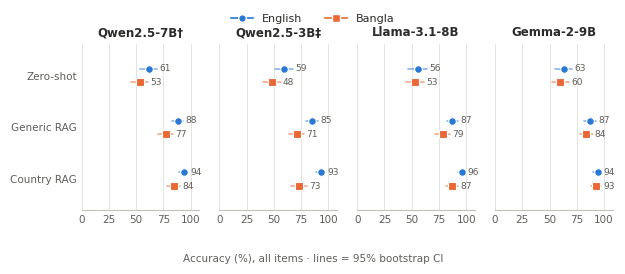

In [21]:
# ── 10a. Fig 1 — Accuracy by setting × language (RQ1, RQ2, RQ4) ─
acc = R['accuracy'][R['accuracy'].group == 'All']
fig, axes = plt.subplots(1, len(MODELS), figsize=(W, 0.45 * len(SETTINGS) + 1.1), sharex=True, sharey=True, squeeze=False)
ys = {s: i for i, s in enumerate(reversed(SETTINGS))}
for ax, m in zip(axes[0], MODELS):
    for lang, off in zip(LANGS, [0.13, -0.13]):
        d = acc[(acc.model == m) & (acc.lang == lang)]
        for r in d.itertuples():
            y = ys[r.setting] + off
            ax.plot([100 * r.lo, 100 * r.hi], [y, y], color=C_LANG[lang], lw=1.2, alpha=0.55, solid_capstyle='round')
            ax.plot(100 * r.acc, y, MK_LANG[lang], color=C_LANG[lang], ms=5.5, mec='white', mew=0.8, zorder=3)
            ax.text(100 * r.hi + 2, y, f'{100 * r.acc:.0f}', va='center', fontsize=6.5, color=INK2)
    ax.set_title(plain(m)); xgrid(ax); ax.set_xlim(0, 108); ax.set_xticks([0, 25, 50, 75, 100])
axes[0][0].set_yticks(list(ys.values())); axes[0][0].set_yticklabels([SETTING_NAME[s] for s in ys])
axes[0][0].set_ylim(-0.6, len(SETTINGS) - 0.4)
fig.legend([Line2D([], [], marker=MK_LANG[l], color=C_LANG[l], lw=1.2, ms=5.5, mec='white') for l in LANGS],
           [LANG_NAME[l] for l in LANGS], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.04))
fig.supxlabel('Accuracy (%), all items · lines = 95% bootstrap CI', fontsize=7.5, color=INK2, y=-0.02)
fig.tight_layout(); save(fig, 'fig1_accuracy')

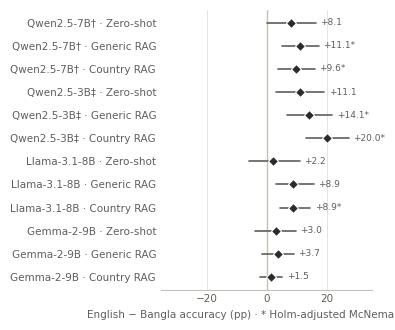

In [22]:
# ── 10b. Fig 2 — Bangla–English gap (RQ2) ──────────────────
g = R['bn_gap'][R['bn_gap'].group == 'All'].copy()
g['row'] = [f'{plain(m)} · {SETTING_NAME[s]}' for m, s in zip(g.model, g.setting)]
fig, ax = plt.subplots(figsize=(W * 0.62, 0.22 * len(g) + 0.7))
y = np.arange(len(g))[::-1]
ax.axvline(0, color=AXIS, lw=1)
for yi, r in zip(y, g.itertuples()):
    ax.plot([100 * r.lo, 100 * r.hi], [yi, yi], color=INK2, lw=1.2, solid_capstyle='round')
    ax.plot(100 * r.delta, yi, 'D', color=INK, ms=5, mec='white', mew=0.8, zorder=3)
    star = '*' if (not pd.isna(r.p_holm) and r.p_holm < 0.05) else ''
    ax.text(max(100 * r.hi, 0) + 1.5, yi, f'{100 * r.delta:+.1f}{star}', va='center', fontsize=6.5, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(g.row); xgrid(ax)
lim = np.nanmax(np.abs(100 * g[['lo', 'hi']].values)) + 8 if len(g) else 10
ax.set_xlim(-lim, lim)
ax.set_xlabel('English − Bangla accuracy (pp) · * Holm-adjusted McNemar p < 0.05', fontsize=7.5, color=INK2)
fig.tight_layout(); save(fig, 'fig2_bangla_gap')

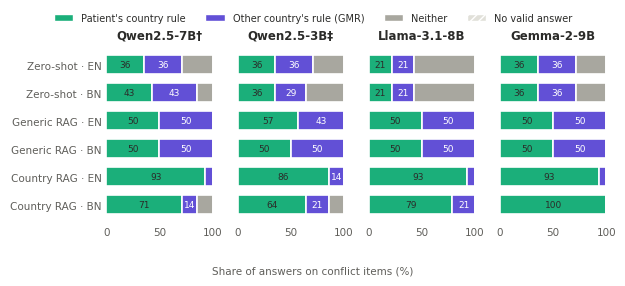

In [23]:
# ── 10c. Fig 3 — Conflict items: whose rule does the model follow? (RQ3) ─
K = R['conflict'][R['conflict'].patient_in == 'both'].copy()
seg = [('correct', "Patient's country rule", C_OK), ('gmr', "Other country's rule (GMR)", C_OTHER),
       ('neither', 'Neither', C_NEITHER), ('fail', 'No valid answer', C_FAIL)]
nrow = len(SETTINGS) * len(LANGS)
fig, axes = plt.subplots(1, len(MODELS), figsize=(W, 0.24 * nrow + 1.1), sharey=True, squeeze=False)
labels = [f'{SETTING_NAME[s]} · {l.upper()}' for s in SETTINGS for l in LANGS]
for ax, m in zip(axes[0], MODELS):
    for yi, (s, l) in enumerate([(s, l) for s in SETTINGS for l in LANGS][::-1]):
        r = K[(K.model == m) & (K.setting == s) & (K.lang == l)]
        if r.empty: continue
        r, left = r.iloc[0], 0.0
        for col, _, colr in seg:
            v = 0 if pd.isna(r[col]) else 100 * r[col]
            ax.barh(yi, v, left=left, height=0.68, color=colr, edgecolor='white', lw=1.2,
                    hatch='////' if col == 'fail' else None)
            if v >= 12 and col in ('correct', 'gmr'):
                ax.text(left + v / 2, yi, f'{v:.0f}', ha='center', va='center', fontsize=6.5,
                        color='white' if col == 'gmr' else INK)
            left += v
    ax.set_title(plain(m)); ax.set_xlim(0, 100); ax.set_xticks([0, 50, 100])
    for sp in ['left', 'bottom']: ax.spines[sp].set_visible(False)
axes[0][0].set_yticks(range(nrow)); axes[0][0].set_yticklabels(labels[::-1])
fig.legend([Patch(fc=c, ec='white', hatch='////' if k == 'fail' else None) for k, _, c in seg], [n for _, n, _ in seg],
           loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.05), fontsize=7)
fig.supxlabel('Share of answers on conflict items (%)', fontsize=7.5, color=INK2, y=-0.02)
fig.tight_layout(); save(fig, 'fig3_conflict_gmr')

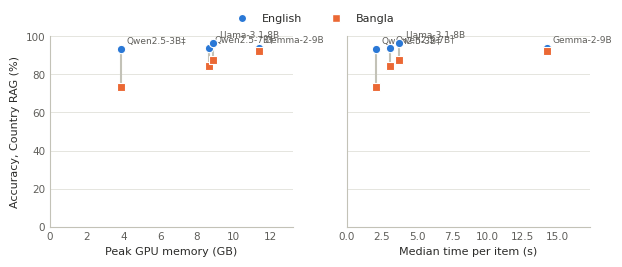

In [24]:
# ── 10c2. Fig 4 — Accuracy vs. offline cost (deployability) ─
DP = R['deploy']; A2 = R['accuracy']
A2 = A2[(A2.group == 'All') & (A2.setting == 'rag_country')]
panels = [('vram_peak_gb', 'Peak GPU memory (GB)'), ('median_latency_s', 'Median time per item (s)')]
fig, axes = plt.subplots(1, 2, figsize=(W, 2.5), sharey=True)
for ax, (col, xl) in zip(axes, panels):
    for m in MODELS:
        if m not in set(DP.model) or col not in DP or pd.isna(DP.set_index('model').loc[m, col]): continue
        x = DP.set_index('model').loc[m, col]
        ys = {l: 100 * A2[(A2.model == m) & (A2.lang == l)].acc.mean() for l in LANGS}
        ax.plot([x, x], [ys['en'], ys['bn']], color=AXIS, lw=1.5, zorder=1)
        for l in LANGS:
            ax.plot(x, ys[l], MK_LANG[l], color=C_LANG[l], ms=6, mec='white', mew=0.8, zorder=3)
        ax.annotate(plain(m), (x, max(ys.values())), xytext=(4, 4), textcoords='offset points', fontsize=6.5, color=INK2)
    ax.set_xlabel(xl); ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.margins(x=0.25); ax.set_xlim(left=0)
axes[0].set_ylabel('Accuracy, Country RAG (%)'); axes[0].set_ylim(0, 100)
fig.legend([Line2D([], [], marker=MK_LANG[l], color=C_LANG[l], lw=0, ms=6, mec='white') for l in LANGS],
           [LANG_NAME[l] for l in LANGS], loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout(); save(fig, 'fig4_deployability')

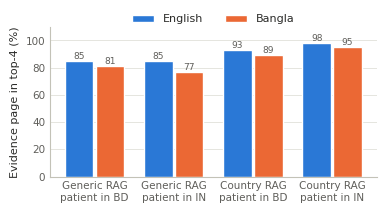

Figures → /kaggle/working/DengueLLM/eval/figures


In [25]:
# ── 10d. Fig S1 — Retrieval: evidence page in top-k (supplementary) ─
rt = R['retrieval']
cats = [(s, c) for s in [x for x in SETTINGS if x != 'zeroshot'] for c in ['BD', 'IN']]
fig, ax = plt.subplots(figsize=(W * 0.62, 2.2))
x = np.arange(len(cats)); bw = 0.36
for k, lang in enumerate(LANGS):
    vals = [100 * rt[(rt.setting == s) & (rt.country == c) & (rt.lang == lang)].evidence_recall.mean() for s, c in cats]
    xs = x + (k - 0.5) * (bw + 0.03)
    ax.bar(xs, vals, width=bw, color=C_LANG[lang], label=LANG_NAME[lang], edgecolor='white', lw=1)
    for xi, v in zip(xs, vals):
        if not np.isnan(v): ax.text(xi, v + 1.5, f'{v:.0f}', ha='center', fontsize=6.5, color=INK2)
ax.set_xticks(x); ax.set_xticklabels([f'{SETTING_NAME[s]}\npatient in {c}' for s, c in cats])
ax.set_ylim(0, 110); ax.set_ylabel(f'Evidence page in top-{TOP_K} (%)')
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.spines['bottom'].set_color(AXIS)
ax.legend(loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.15))
fig.tight_layout(); save(fig, 'figS1_retrieval')
print('Figures →', FIG_DIR)

In [26]:
# ── 11. Sanity checks (review before writing the paper) ───
print('Predicted-letter distribution (%), to check position bias:')
print(R['letters'].to_string(index=False))
print('\nFormat-failure examples (3 per model):')
for m in MODELS:
    ex = raw[(raw.model == m) & (raw.fail == 1)].response.head(3).tolist()
    print(f'  {m}: {ex}')
print('\nFinish reason (length = cut off at max_new_tokens):'); print(raw.groupby('model').finish.value_counts().unstack(fill_value=0))

Predicted-letter distribution (%), to check position bias:
           model    A    B    C    D  fail
       gemma2-9b 22.7 27.2 26.0 23.5   0.6
     llama3.1-8b 31.6 24.9 21.4 21.5   0.6
      qwen2.5-3b 27.7 22.1 24.3 25.9   0.0
      qwen2.5-7b 25.9 29.4 24.1 20.6   0.0
gold (benchmark) 25.9 25.2 23.7 25.2   0.0

Format-failure examples (3 per model):
  qwen2.5-7b: []
  qwen2.5-3b: []
  llama3.1-8b: ['ভারতের জাতীয় ডেঙ্�', 'বাংলাদেশের জাতীয় �', 'ভারতের জাতীয় ডেঙ্�']
  gemma2-9b: ['Answer:  The provided text does not contain the answer to this question.', 'Answer:  None of the provided options are mentioned in the text.', 'Answer:  None of the above']

Finish reason (length = cut off at max_new_tokens):
finish       length  stop
model                    
gemma2-9b         0   810
llama3.1-8b       6   804
qwen2.5-3b        0   810
qwen2.5-7b        0   810


In [27]:
# ── 12. Kaggle: zip all results for download (Kaggle clears files after a session) ─
if IN_KAGGLE:
    z = shutil.make_archive('/kaggle/working/dengue_eval_results', 'zip', OUT)
    print('Download this file:', z, '\nTo resume in a later session, add this version\'s output (or the raw/ folder) as an input')
else:
    print('Colab: all results are in Google Drive ->', OUT)

Download this file: /kaggle/working/dengue_eval_results.zip 
To resume in a later session, add this version's output (or the raw/ folder) as an input


In [28]:
# ── 13. Final analysis: corrected deployability table + error analysis ──
# Uses only scored_responses.csv and raw/deploy_*.csv, so it runs in seconds (no GPU, no model reload).
import os, glob, re
import numpy as np, pandas as pd

OUT_DIR = OUT if 'OUT' in globals() else '/kaggle/working/DengueLLM/eval'
TAB, FIG = f'{OUT_DIR}/tables', f'{OUT_DIR}/figures'
os.makedirs(TAB, exist_ok=True); os.makedirs(FIG, exist_ok=True)
S = pd.read_csv(f'{OUT_DIR}/scored_responses.csv', dtype=str, keep_default_na=False)
for c in ['correct', 'mismatch', 'fail', 'latency_s', 'n_in_tokens', 'n_out_tokens']:
    S[c] = pd.to_numeric(S[c], errors='coerce')
S['is_conflict'] = S['set'] == 'CONFLICT'

NAMES = {'qwen2.5-7b': 'Qwen2.5-7B', 'qwen2.5-3b': 'Qwen2.5-3B', 'llama3.1-8b': 'Llama-3.1-8B', 'gemma2-9b': 'Gemma-2-9B'}
for m in sorted(set(S.model)): NAMES.setdefault(m, m)   # e.g. mock models in PIPELINE_TEST
ORDER = [m for m in NAMES if m in set(S.model)]
SET_NAME = {'zeroshot': 'Zero-shot', 'rag_generic': 'Generic RAG', 'rag_country': 'Country RAG'}

def to_latex(df, caption, label, note=''):
    esc = lambda s: str(s).replace('%', '\\%').replace('&', '\\&').replace('_', '\\_').replace('−', '$-$')
    cols = 'l' + 'r' * (df.shape[1] - 1)
    rows = [' & '.join(esc(v) for v in r) + ' \\\\' for r in df.astype(str).values]
    out = ['\\begin{table}[t]', '\\centering', '\\footnotesize', f'\\caption{{{caption}}}', f'\\label{{{label}}}',
           f'\\begin{{tabular}}{{{cols}}}', '\\toprule', ' & '.join(esc(c) for c in df.columns) + ' \\\\', '\\midrule',
           *rows, '\\bottomrule', '\\end{tabular}']
    if note: out.append(f'\\par\\smallskip\\parbox{{\\linewidth}}{{\\scriptsize {esc(note)}}}')
    return '\n'.join(out + ['\\end{table}'])

def save(df, name, caption, label, note=''):
    df.to_csv(f'{TAB}/{name}.csv', index=False, encoding='utf-8-sig')
    with open(f'{TAB}/{name}.tex', 'w', encoding='utf-8') as fh: fh.write(to_latex(df, caption, label, note))
    print(f'\n== {name} ==\n{df.to_string(index=False)}')

# ---------- T6 (corrected): deployability ----------
dep = pd.concat([pd.read_csv(f) for f in glob.glob(f'{OUT_DIR}/raw/deploy_*.csv')], ignore_index=True)
rows = []
for m in ORDER:
    d, dm = S[S.model == m], dep[dep.model == m].iloc[-1]
    tot = d.n_in_tokens + d.n_out_tokens
    best = d[d.setting == 'rag_country'].groupby('lang').correct.mean()
    rows.append({'Model': NAMES[m], 'Licence': dm.license, 'Compute dtype': dm.compute_dtype,
                 'Weights (GB)': f'{dm.weights_footprint_gb:.2f}', 'Peak VRAM (GB)': f'{dm.vram_peak_gb:.2f}',
                 'Load (s)': f'{dm.load_s:.0f}',
                 'Median s/item EN': f"{d[d.lang == 'en'].latency_s.median():.2f}",
                 'Median s/item BN': f"{d[d.lang == 'bn'].latency_s.median():.2f}",
                 'Tokens/s (prompt+output)': f'{tot.sum() / d.latency_s.sum():.0f}',
                 'Median prompt tokens EN / BN': f"{d[d.lang == 'en'].n_in_tokens.median():.0f} / {d[d.lang == 'bn'].n_in_tokens.median():.0f}",
                 'Country-RAG acc EN / BN (%)': f"{100 * best.get('en', np.nan):.1f} / {100 * best.get('bn', np.nan):.1f}"})
save(pd.DataFrame(rows), 'T6_deploy_v2', 'Offline deployability on one NVIDIA T4 (16 GB), 4-bit NF4, batch 1.', 'tab:deploy',
     'Gemma-2 used fp32 compute because fp16 can overflow for Gemma-2 and the T4 has no bf16; its timing is therefore not '
     'directly comparable. Tokens/s counts prompt and generated tokens, since answers are only a few tokens long.')

# ---------- E1: country-insensitivity on CONFLICT items ----------
# For each conflict item, does the model give the same option whether the patient is in Bangladesh or India?
c = S[S.is_conflict].pivot_table(index=['model', 'setting', 'lang', 'qid'], columns='country', values='pred', aggfunc='first').reset_index()
c['same'] = (c['BD'] == c['IN']) & (c['BD'] != '')
e1 = (c.groupby(['model', 'setting', 'lang']).same.mean().mul(100).round(1).unstack('lang').reset_index())
e1['Model'] = e1.model.map(NAMES); e1['Setting'] = e1.setting.map(SET_NAME)
e1 = e1.sort_values(['model', 'setting'], key=lambda s: s.map({**{m: i for i, m in enumerate(ORDER)}, **{k: i for i, k in enumerate(SET_NAME)}}))
e1 = e1[['Model', 'Setting', 'en', 'bn']].rename(columns={'en': 'Same answer for BD & IN patient, EN (%)', 'bn': 'BN (%)'})
save(e1, 'E1_country_insensitivity', 'Share of conflict items where the model gives the same option for a Bangladeshi and an Indian patient.',
     'tab:insensitive', '100% means the stated patient country never changed the answer.')

# ---------- E2: accuracy by topic (Country RAG) ----------
t = S[S.setting == 'rag_country'].groupby(['topic', 'model', 'lang']).correct.mean().mul(100).round(1).unstack(['model', 'lang'])
t.columns = [f'{NAMES[m]} {l.upper()}' for m, l in t.columns]
n_items = S[S.model == ORDER[0]].drop_duplicates('qid').groupby('topic').size()
t.insert(0, 'Items', n_items); t = t.reset_index().rename(columns={'topic': 'Topic'}).sort_values('Items', ascending=False)
save(t, 'E2_topic_accuracy', 'Country-RAG accuracy (%) by clinical topic.', 'tab:topic')

# ---------- E3: items every model gets wrong with Country RAG (for qualitative examples) ----------
cr = S[(S.setting == 'rag_country') & (S.lang == 'en')]
wrong = cr.groupby('uid').correct.sum()
hard = cr[cr.uid.isin(wrong[wrong == 0].index)].drop_duplicates('uid')
bench_path = next(iter(glob.glob('/kaggle/input/**/benchmark.csv', recursive=True)), f'{DATA_DIR}/benchmark.csv' if 'DATA_DIR' in globals() else '')
B = pd.read_csv(bench_path, dtype=str, keep_default_na=False).set_index('qid') if bench_path and os.path.exists(bench_path) else None
rows = []
for _, r in hard.iterrows():
    preds = {NAMES[m]: S[(S.uid == r.uid) & (S.setting == 'rag_country') & (S.model == m)].pred.iloc[0] for m in ORDER}
    q = B.loc[r.qid] if B is not None else None
    rows.append({'qid': r.qid, 'Set': r['set'], 'Patient': r.country, 'Topic': r.topic, 'Gold': r.gold,
                 'Gold text': q[f'{r.gold}_en'] if q is not None else '', 'Predictions': ', '.join(f'{k}: {v or "-"}' for k, v in preds.items()),
                 'Question': q.question_en if q is not None else ''})
e3 = pd.DataFrame(rows)
e3.to_csv(f'{TAB}/E3_all_models_wrong.csv', index=False, encoding='utf-8-sig')
print(f'\n== E3: {len(e3)} English units wrong for all models under Country RAG (saved for manual error analysis) ==')
if len(e3): print(e3[['qid', 'Set', 'Patient', 'Topic', 'Gold', 'Predictions']].to_string(index=False))

# ---------- E4: format failures (raw text) ----------
ff = S[S.fail == 1][['model', 'setting', 'lang', 'qid', 'response']]
ff.to_csv(f'{TAB}/E4_format_failures.csv', index=False, encoding='utf-8-sig')
print(f'\n== E4: {len(ff)} format failures ==')
print(ff.groupby(['model', 'setting', 'lang']).size().to_string())

# ---------- E5: answer-position bias ----------
pos = S[S.pred != ''].groupby('model').pred.value_counts(normalize=True).mul(100).round(1).unstack(fill_value=0)
pos.index = pos.index.map(NAMES)
gold = S[S.model == ORDER[0]].gold.value_counts(normalize=True).mul(100).round(1)
pos.loc['Benchmark gold'] = gold
pos = pos.reset_index().rename(columns={'model': 'Model'})
save(pos, 'E5_position_bias', 'Distribution of predicted options (%) vs. gold.', 'tab:position')

if 'IN_KAGGLE' in globals() and IN_KAGGLE:
    import shutil
    print('\nZip:', shutil.make_archive('/kaggle/working/dengue_eval_results', 'zip', OUT_DIR))


== T6_deploy_v2 ==
       Model             Licence Compute dtype Weights (GB) Peak VRAM (GB) Load (s) Median s/item EN Median s/item BN Tokens/s (prompt+output) Median prompt tokens EN / BN Country-RAG acc EN / BN (%)
  Qwen2.5-7B          Apache-2.0       float16         5.44           8.63      119             2.87             4.05                      617                  2046 / 2476                 94.1 / 84.4
  Qwen2.5-3B       Qwen Research       float16         2.01           3.86       44             1.91             2.71                      919                  2046 / 2476                 93.3 / 73.3
Llama-3.1-8B Llama 3.1 Community       float16         5.59           8.90      113             3.58             5.29                      493                  2029 / 2508                 96.3 / 87.4
  Gemma-2-9B  Gemma Terms of Use       float32         7.83          11.36      154            13.34            15.48                      132                  1913 / 2096         